
# CS 370 Assignment 4 — Q5

This notebook solves Q5 of Assignment 4.

It does the following:
1. Load `operahall.png`.
2. Extract and visualize the top-left 32x32 block.
3. Compute and visualize the 2D FFT of that block.
4. Zero the DC coefficient and visualize again.
5. Implement `Compress(X, tol)` using 32x32 blockwise FFT compression.
6. Search for four tolerance values whose drop ratios are approximately:
   - 0.50
   - 0.70
   - 0.89
   - 0.95
7. Plot the four compressed images.
8. Plot the absolute error image for the least compressed case.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['axes.grid'] = False


Original shape: (512, 512)
dtype: float64
Grayscale shape: (512, 512)


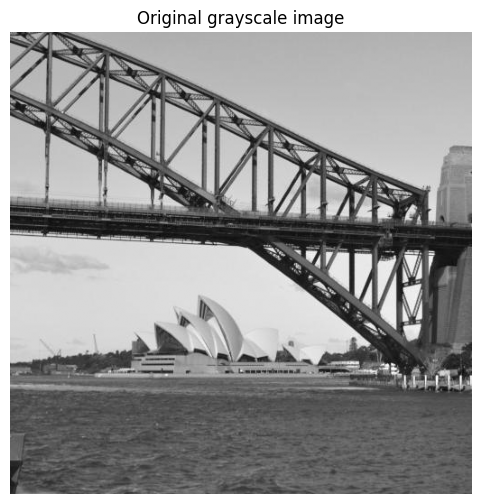

In [4]:

img = np.array(plt.imread('operahall.jpg'), dtype=float)

print("Original shape:", img.shape)
print("dtype:", img.dtype)

# Handle possible RGB / RGBA input by converting to grayscale
if img.ndim == 3:
    if img.shape[2] >= 3:
        img = img[..., :3].mean(axis=2)

print("Grayscale shape:", img.shape)

plt.imshow(img, cmap='gray')
plt.title('Original grayscale image')
plt.axis('off')
plt.show()


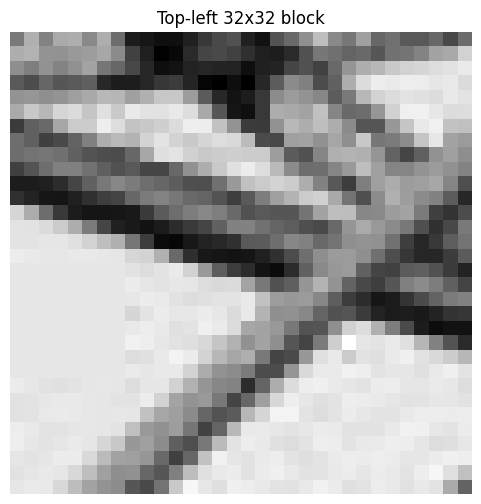

In [5]:

block = img[:32, :32]

plt.imshow(block, cmap='gray')
plt.title('Top-left 32x32 block')
plt.axis('off')
plt.show()


Brightest pixel index in |F|: (np.int64(0), np.int64(0))
Brightest value: 132857.0
Interpretation: this is typically the DC coefficient (average intensity component).


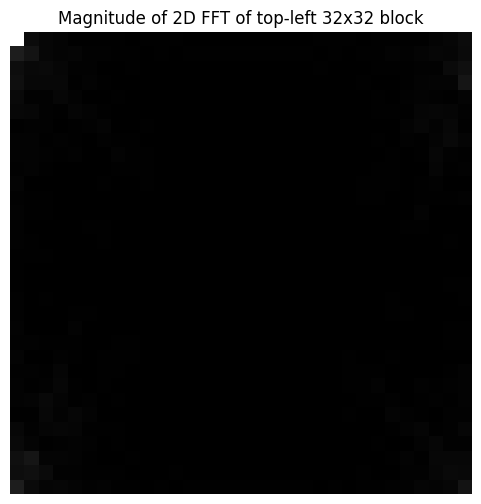

In [6]:

F = np.fft.fft2(block)
Fmag = np.abs(F)

brightest_idx = np.unravel_index(np.argmax(Fmag), Fmag.shape)
brightest_val = Fmag[brightest_idx]

print("Brightest pixel index in |F|:", brightest_idx)
print("Brightest value:", brightest_val)
print("Interpretation: this is typically the DC coefficient (average intensity component).")

plt.imshow(Fmag, cmap='gray')
plt.title('Magnitude of 2D FFT of top-left 32x32 block')
plt.axis('off')
plt.show()


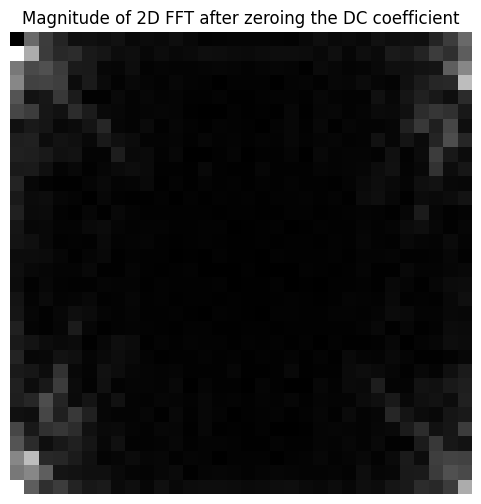

In [7]:

F_zero_dc = F.copy()
F_zero_dc[0, 0] = 0

plt.imshow(np.abs(F_zero_dc), cmap='gray')
plt.title('Magnitude of 2D FFT after zeroing the DC coefficient')
plt.axis('off')
plt.show()


In [8]:

def Compress(X, tol):
    X = np.array(X, dtype=float)
    m, n = X.shape
    
    # We assume dimensions are multiples of 32 as per the assignment.
    Y = np.zeros_like(X, dtype=float)
    
    total_nonzero_original = 0
    total_nonzero_dropped = 0
    
    for i in range(0, m, 32):
        for j in range(0, n, 32):
            block = X[i:i+32, j:j+32]
            F = np.fft.fft2(block)
            magF = np.abs(F)
            Fmax = np.max(magF)
            
            original_nonzero = np.count_nonzero(F)
            mask_drop = (magF <= Fmax * tol) & (F != 0)
            dropped_nonzero = np.count_nonzero(mask_drop)
            
            F_filtered = F.copy()
            F_filtered[mask_drop] = 0
            
            block_rec = np.real(np.fft.ifft2(F_filtered))
            Y[i:i+32, j:j+32] = block_rec
            
            total_nonzero_original += original_nonzero
            total_nonzero_dropped += dropped_nonzero
    
    drop = 0.0
    if total_nonzero_original > 0:
        drop = total_nonzero_dropped / total_nonzero_original
    
    return Y, drop


Test drop ratio at tol=0.10: 0.9969761884507412


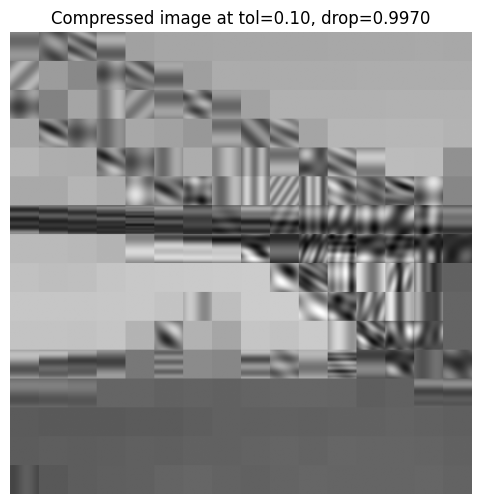

In [9]:

# Quick sanity check
Y_test, drop_test = Compress(img, 0.10)
print("Test drop ratio at tol=0.10:", drop_test)

plt.imshow(Y_test, cmap='gray')
plt.title(f'Compressed image at tol=0.10, drop={drop_test:.4f}')
plt.axis('off')
plt.show()



## Find tol values giving target drop ratios

We search over a dense grid of tolerance values and keep the values whose drop ratios are closest to the targets.


In [10]:

targets = [0.50, 0.70, 0.89, 0.95]
tol_grid = np.linspace(0.0, 0.5, 101)

results = []
for tol in tol_grid:
    _, drop = Compress(img, float(tol))
    results.append((float(tol), float(drop)))

best = {}
for target in targets:
    best[target] = min(results, key=lambda x: abs(x[1] - target))

print("Best tol values found:")
for target in targets:
    tol_star, drop_star = best[target]
    print(f"target={target:.2f}, tol={tol_star:.4f}, drop={drop_star:.4f}")


Best tol values found:
target=0.50, tol=0.0050, drop=0.8400
target=0.70, tol=0.0050, drop=0.8400
target=0.89, tol=0.0100, drop=0.9262
target=0.95, tol=0.0150, drop=0.9557


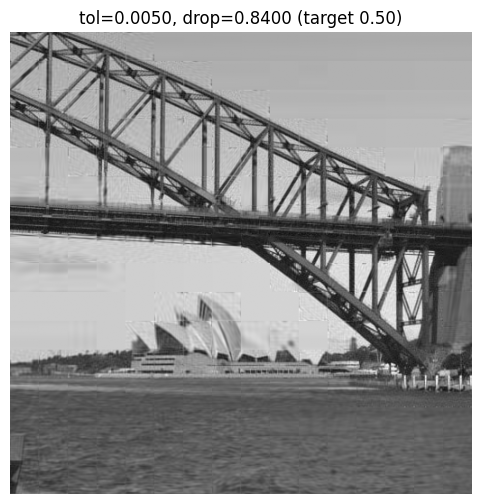

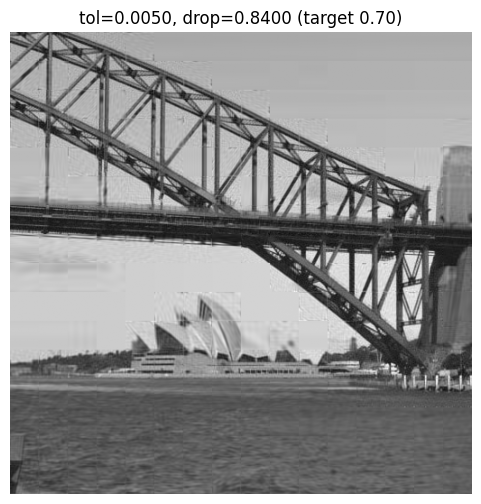

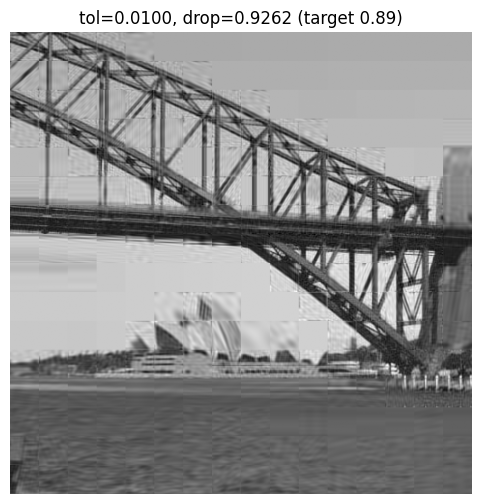

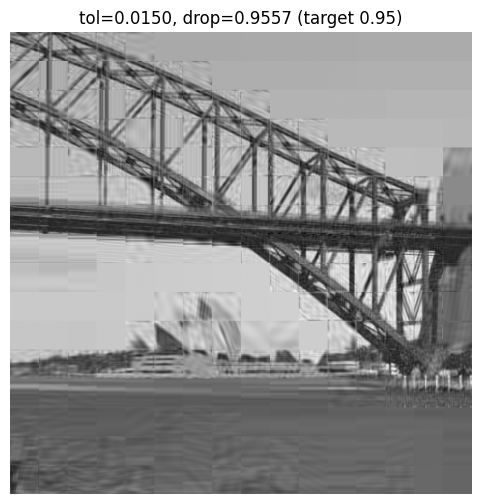

In [11]:

compressed_outputs = []

for target in targets:
    tol_star, drop_star = best[target]
    Yc, drop_actual = Compress(img, tol_star)
    compressed_outputs.append((target, tol_star, Yc, drop_actual))

for target, tol_star, Yc, drop_actual in compressed_outputs:
    plt.figure(figsize=(6,6))
    plt.imshow(Yc, cmap='gray')
    plt.title(f'tol={tol_star:.4f}, drop={drop_actual:.4f} (target {target:.2f})')
    plt.axis('off')
    plt.show()


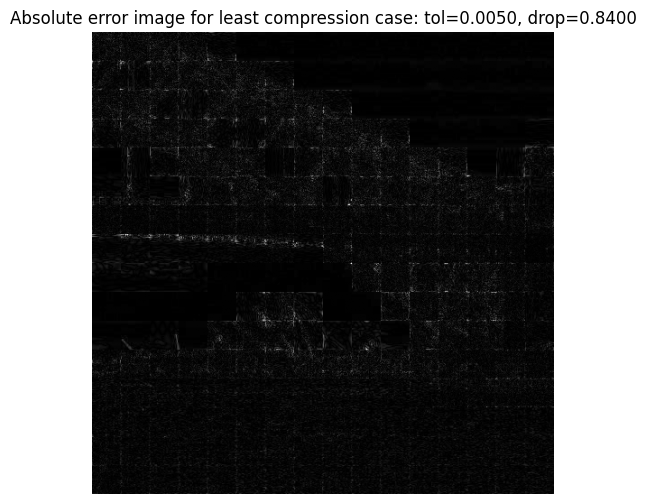

Least compression case:
target = 0.5
tol = 0.005
drop = 0.84002026185744


In [12]:

# Least compression = smallest target drop ratio, i.e. about 0.50
target, tol_star, Y_best, drop_actual = compressed_outputs[0]

err = np.abs(img - Y_best)

plt.figure(figsize=(6,6))
plt.imshow(err, cmap='gray')
plt.title(f'Absolute error image for least compression case: tol={tol_star:.4f}, drop={drop_actual:.4f}')
plt.axis('off')
plt.show()

print("Least compression case:")
print("target =", target)
print("tol =", tol_star)
print("drop =", drop_actual)
